# Validação de Opções e Superfícies de Volatilidade (Manuais B3 e Bloomberg)

Este caderno documenta e valida os modelos de precificação de opções e construção de superfícies de volatilidade implícita implementados no núcleo Cython `options_core` e nos módulos `bz_pricing.instruments.options` e `bz_pricing.volatility`:
1. Opções sobre ações, ETFs e índices (`EquityOption`, modelos Black-Scholes-Merton europeu e árvore binomial Cox-Ross-Rubinstein americana, além de `CorradoSuOption`).
2. Opções sobre moedas (`FXOption`, Garman-Kohlhagen com curva `PRE` e cupom cambial e ajuste de *fixing*) e opções sobre juros (`IDIOption` e `DI1Option`).
3. Calibração e interpolação de superfícies de volatilidade (`SVISlice`, `SABRSlice`, `VolatilitySurface`, conversão $\Delta \leftrightarrow K$, variância total $\sigma^2 T$ e auditoria de não arbitragem).
4. Precificação em lote de carteira de opções via Cython (`price_options_portfolio`).

In [1]:
import datetime, math, os, time
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from bz_pricing.curves import CurveManager
from bz_pricing.instruments import (
    EquityOption,
    FXOption,
    IDIOption,
    DI1Option,
    CorradoSuOption,
    Swaption,
    CapFloor,
    BarrierOption,
    AsianOption,
    price_options_portfolio,
)
from bz_pricing.volatility import (
    SVISlice,
    SABRSlice,
    VolatilitySurface,
    delta_to_strike,
    strike_to_delta,
    infer_forward_from_put_call_parity,
)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
ref_dt = datetime.date(2026, 11, 12)
cm = CurveManager(allow_download=True)
curva_pre = cm.get_curve('PRE', ref_dt)


## 1. Opções de Renda Variável (`EquityOption` e `CorradoSuOption`)

Avaliam-se opções europeias e americanas com taxa livre de risco contínua $r_n = \ln(1 + T_{	ext{PreDI1},n})$ extraída da curva `PRE` da B3, cálculo completo de gregas de primeira e segunda ordem (`delta`, `gamma`, `vega`, `theta`, `rho`, `vanna` e `volga`), verificação da paridade *Put-Call*, inversão de volatilidade implícita em Cython e comparação com o modelo de Corrado & Su.

In [2]:
mat_eq = datetime.date(2027, 5, 17)
spot_eq, strike_eq, vol_eq, q_div = 38.50, 40.00, 0.32, 0.04

c_eu = EquityOption('PETRC400', mat_eq, strike_eq, 'CALL', 'EUROPEAN')
p_eu = EquityOption('PETRO400', mat_eq, strike_eq, 'PUT',  'EUROPEAN')
p_am = EquityOption('PETRO400A', mat_eq, strike_eq, 'PUT', 'AMERICAN')
cs_c = CorradoSuOption('PETRC400CS', mat_eq, strike_eq, 'CALL')

mc = c_eu.risk_metrics(ref_dt, spot_eq, curva_pre, vol_eq, q_div)
mp = p_eu.risk_metrics(ref_dt, spot_eq, curva_pre, vol_eq, q_div)
ma = p_am.risk_metrics(ref_dt, spot_eq, curva_pre, vol_eq, q_div, crr_steps=300)

paridade_lhs = mc['price'] - mp['price']
paridade_rhs = spot_eq * math.exp(-mc['q_cont'] * mc['T']) - strike_eq * math.exp(-mc['r_cont'] * mc['T'])
iv_rec = c_eu.implied_volatility(ref_dt, mc['price'], spot_eq, curva_pre, q_div)
p_cs = cs_c.price(ref_dt, spot_eq, curva_pre, vol_eq, kappa3=-0.35, kappa4=4.2, carry_or_div_yield=q_div)

print(f"Erro na paridade Put-Call: {abs(paridade_lhs - paridade_rhs):.2e}")
print(f"Vol implícita recuperada:  {iv_rec*100:.6f}% (entrada: {vol_eq*100:.6f}%)")
print(f"Corrado & Su (kappa3=-0.35, kappa4=4.2): R$ {p_cs:.4f} vs BSM: R$ {mc['price']:.4f}")

pd.DataFrame([
    {'ativo': c_eu.ticker, 'tipo': 'CALL EU', **mc},
    {'ativo': p_eu.ticker, 'tipo': 'PUT EU',  **mp},
    {'ativo': p_am.ticker, 'tipo': 'PUT AM (CRR)', **ma},
])[['ativo', 'tipo', 'du', 'price', 'delta', 'gamma', 'vega_1pct', 'theta_du', 'rho', 'vanna', 'volga']]

Erro na paridade Put-Call: 0.00e+00
Vol implícita recuperada:  32.000000% (entrada: 32.000000%)
Corrado & Su (kappa3=-0.35, kappa4=4.2): R$ 3.2758 vs BSM: R$ 3.5029


,ativo,tipo,du,price,delta,gamma,vega_1pct,theta_du,rho,vanna,volga
0,PETRC400,CALL EU,125.0,3.502860,0.545791,0.044638,0.105024,-0.019182,8.685567,0.100752,-0.388302
1,PETRO400,PUT EU,125.0,3.253095,-0.434942,0.044638,0.105024,-0.005760,-9.919824,0.100752,-0.388302
2,PETRO400A,PUT AM (CRR),125.0,3.526838,-0.489776,0.055262,0.103090,-0.008059,-6.702870,0.100752,-0.388302


## 2. Opções de Câmbio (`FXOption`) e Juros (`IDIOption` e `DI1Option`)

Para moedas (`USD/BRL`), a taxa doméstica $r_n$ provém da curva `PRE` e a taxa estrangeira contínua $q_n$ é derivada do cupom cambial limpo (`DOC` em base `DC/360`), com opção de ajuste de *fixing* ($t-1$). Para juros, validam-se opções sobre `IDI` e sobre futuro de `DI1` com inversão de volatilidade implícita via Black-76.

In [3]:
mat_fx = datetime.date(2027, 2, 1)
fx_c = FXOption('DOLC580', mat_fx, 5.80, 'CALL')
fx_p = FXOption('DOLP580', mat_fx, 5.80, 'PUT')
m_fx_c = fx_c.risk_metrics(ref_dt, spot_ptax=5.75, pre_rate_or_curve=curva_pre, cupom_limpo_or_curve=0.055, vol=0.16)
m_fx_adj = fx_c.risk_metrics(ref_dt, spot_ptax=5.75, pre_rate_or_curve=curva_pre, cupom_limpo_or_curve=0.055, vol=0.16, fixing_vol_adjust=True)

idi_c = IDIOption('IDIC300', mat_fx, 295000.0, 'CALL')
m_idi = idi_c.risk_metrics(ref_dt, idi_spot=286000.0, pre_rate_or_curve=curva_pre, vol=0.045)
iv_idi = idi_c.implied_volatility(ref_dt, m_idi['price'], idi_spot=286000.0, pre_rate_or_curve=curva_pre)

di1_c = DI1Option('DI1C15', mat_fx, datetime.date(2028, 1, 3), strike_rate=0.15, option_type='CALL')
m_di1 = di1_c.risk_metrics(ref_dt, pu_c=97100.0, pu_l=85800.0, vol=0.18)
iv_di1 = di1_c.implied_volatility(ref_dt, m_di1['price'], pu_c=97100.0, pu_l=85800.0)

pd.DataFrame([
    {'contrato': fx_c.ticker, 'modelo': 'Garman-Kohlhagen', 'preco': m_fx_c['price'], 'delta': m_fx_c['delta'], 'vega_1pct': m_fx_c['vega_1pct'], 'iv_check_%': fx_c.implied_volatility(ref_dt, m_fx_c['price'], 5.75, curva_pre, 0.055)*100},
    {'contrato': f'{fx_c.ticker} (fixing)', 'modelo': 'GK + Ajuste DU/(DU+1)', 'preco': m_fx_adj['price'], 'delta': m_fx_adj['delta'], 'vega_1pct': m_fx_adj['vega_1pct'], 'iv_check_%': m_fx_adj['vol_eff']*100},
    {'contrato': idi_c.ticker, 'modelo': 'Black-76 IDI', 'preco': m_idi['price'], 'delta': m_idi['delta'], 'vega_1pct': m_idi['vega_1pct'], 'iv_check_%': iv_idi*100},
    {'contrato': di1_c.ticker, 'modelo': 'Black-76 DI1 FRA', 'preco': m_di1['price'], 'delta': m_di1['delta'], 'vega_1pct': m_di1['vega_1pct'], 'iv_check_%': iv_di1*100},
])

,contrato,modelo,preco,delta,vega_1pct,iv_check_%
0,DOLC580,Garman-Kohlhagen,0.186348,0.543052,0.010407,16.000000
1,DOLC580 (fixing),GK + Ajuste DU/(DU+1),0.184828,0.543237,0.010407,15.853878
2,IDIC300,Black-76 IDI,1912.461157,0.425444,521.631422,4.500000
3,DI1C15,Black-76 DI1 FRA,188.973284,24478.434096,17.419611,18.000000


## 3. Superfícies de Volatilidade Implícita (`SVI`, `SABR`, Spline Monótono e Não Arbitragem)

Calibram-se fatias `SVISlice` em dois vencimentos (63 e 126 dias úteis) e uma fatia `SABRSlice` para taxas de juros. Em seguida, constrói-se a `VolatilitySurface`, executa-se a interpolação temporal em variância total $\sigma^2 T$, verifica-se a conversão bidirecional $\Delta \leftrightarrow K$ e audita-se a ausência de arbitragem de *strike*, borboleta e calendário.

Auditoria de não arbitragem B3: {'passed': True, 'strike_monotonicity_violations': 0, 'butterfly_violations': 0, 'calendar_violations': 0}
Conversão Delta -> Strike -> Delta (25D): K=110.9854 | Delta recuperado=0.250000
Erro máximo de ajuste SABR: 1.70e-12


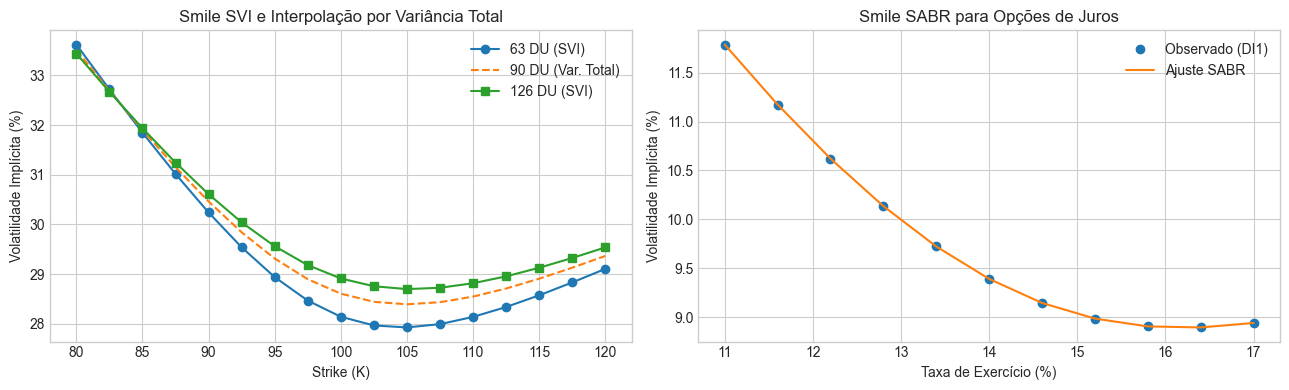

In [4]:
fwd = 100.0
k_grid = np.linspace(80.0, 120.0, 17)
log_m = np.log(k_grid / fwd)

sl_63_ref = SVISlice(a=0.015, b=0.04, rho=-0.35, m=0.0, sigma=0.12, T=63 / 252.0)
sl_126_ref = SVISlice(a=0.032, b=0.07, rho=-0.35, m=0.0, sigma=0.14, T=126 / 252.0)
sl_63_fit = SVISlice.fit(log_m, sl_63_ref.implied_vol(log_m), T=63 / 252.0)
sl_126_fit = SVISlice.fit(log_m, sl_126_ref.implied_vol(log_m), T=126 / 252.0)

surf_svi = VolatilitySurface.from_svi_slices({63: sl_63_fit, 126: sl_126_fit})
arb_res = surf_svi.check_no_arbitrage(forward_by_du=fwd, r_cont_by_du=0.13)
print('Auditoria de não arbitragem B3:', arb_res)

k_25d = delta_to_strike(0.25, fwd, 0.28, 63 / 252.0)
d_back = strike_to_delta(k_25d, fwd, 0.28, 63 / 252.0)
print(f'Conversão Delta -> Strike -> Delta (25D): K={k_25d:.4f} | Delta recuperado={d_back:.6f}')

sabr_ref = SABRSlice(alpha=0.035, beta=0.5, rho=-0.25, nu=0.35, F=0.14, T=0.5)
k_ir = np.linspace(0.11, 0.17, 11)
sabr_fit = SABRSlice.fit(0.14, k_ir, sabr_ref.implied_vol(k_ir), T=0.5, beta=0.5)
print(f'Erro máximo de ajuste SABR: {np.max(np.abs(sabr_fit.implied_vol(k_ir) - sabr_ref.implied_vol(k_ir))):.2e}')

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(k_grid, [surf_svi.get_vol(63, strike=float(k), forward=fwd)*100 for k in k_grid], 'o-', label='63 DU (SVI)')
axes[0].plot(k_grid, [surf_svi.get_vol(90, strike=float(k), forward=fwd)*100 for k in k_grid], '--', label='90 DU (Var. Total)')
axes[0].plot(k_grid, [surf_svi.get_vol(126, strike=float(k), forward=fwd)*100 for k in k_grid], 's-', label='126 DU (SVI)')
axes[0].set_title('Smile SVI e Interpolação por Variância Total')
axes[0].set_xlabel('Strike (K)')
axes[0].set_ylabel('Volatilidade Implícita (%)')
axes[0].legend()

axes[1].plot(k_ir * 100, sabr_ref.implied_vol(k_ir) * 100, 'o', label='Observado (DI1)')
axes[1].plot(k_ir * 100, sabr_fit.implied_vol(k_ir) * 100, '-', label='Ajuste SABR')
axes[1].set_title('Smile SABR para Opções de Juros')
axes[1].set_xlabel('Taxa de Exercício (%)')
axes[1].set_ylabel('Volatilidade Implícita (%)')
axes[1].legend()
plt.tight_layout()
plt.show()

## 4. Benchmark de Precificação em Lote (`price_options_portfolio`)

Avalia-se o desempenho do núcleo Cython `price_options_batch` na precificação conjunta de 1.000 contratos (opções europeias e americanas com árvore binomial CRR).

In [5]:
positions = [
    {'instrument': c_eu, 'spot': spot_eq, 'pre_rate_or_curve': curva_pre, 'vol': 0.31, 'quantity': 100},
    {'instrument': p_am, 'spot': spot_eq, 'pre_rate_or_curve': curva_pre, 'vol': 0.33, 'quantity': -50},
] * 500

t0 = time.perf_counter()
df_batch = price_options_portfolio(positions, ref_dt, crr_steps=120)
elapsed = time.perf_counter() - t0
print(f'Carteira de {len(df_batch)} opções precificada em {elapsed:.4f} s')
df_batch.head(4)

Carteira de 1000 opções precificada em 0.0497 s


,ticker,classe,option_type,exercise,quantity,price,mtm,delta,gamma,vega_1pct,theta_du,rho
0,PETRC400,EquityOption,CALL,EUROPEAN,100.0,3.822903,382.290282,0.590437,0.046236,0.105383,-0.022796,9.379431
1,PETRO400A,EquityOption,PUT,AMERICAN,-50.0,3.413682,-170.684075,-0.483747,0.057895,0.102185,-0.007190,-6.086100
2,PETRC400,EquityOption,CALL,EUROPEAN,100.0,3.822903,382.290282,0.590437,0.046236,0.105383,-0.022796,9.379431
3,PETRO400A,EquityOption,PUT,AMERICAN,-50.0,3.413682,-170.684075,-0.483747,0.057895,0.102185,-0.007190,-6.086100


## 5. Validação Empírica com Séries Reais da B3 (`BVBG_IN` e `BVBG_SPRD`)

A validação empírica da superfície de volatilidade combina o cadastro oficial de instrumentos (`BVBG_IN`) com os preços de fechamento e liquidez do boletim diário (`BVBG_SPRD`) por meio de `B3DataLoader.load_options`. Tomam-se como amostra as opções europeias de dólar comercial (`DOLZ26`, vencimento em 01/12/2026) negociadas em 30/10/2026 e utiliza-se o preço de ajuste do contrato futuro `DOLZ26` como referência *forward*, com a taxa pré-fixada de curto prazo para o desconto.

A fatia SVI é calibrada apenas sobre metade dos *strikes* fora e no dinheiro (`otm_only=True`), com ponderação por vega (`vega_weighted=True`), e testada fora da amostra sobre os demais *strikes* via `validate_slice_out_of_sample`. Em seguida, verificam-se a condição de momentos de Lee (2004) nas asas (`wing_slope_check`), a não negatividade da densidade neutra ao risco via Breeden-Litzenberger (`breeden_litzenberger_density`) e a variância local de Dupire em *moneyness* logarítmico constante (`dupire_local_vol_grid`).


Séries DOLZ26 avaliadas: 12 | DU=20 | Forward=5488.06
Out-of-sample SVI -> RMSE Vol: 163.09 bps | MAE Vol: 117.66 bps | RMSE Preço: 8.7373
Lee wing check passed: True [{'du': 20, 'b': 0.009243056167939525, 'rho': 0.8006920592829944, 'max_slope': 0.016643897845115403, 'passed': True}, {'du': 40, 'b': 0.017561806719085096, 'rho': 0.8006920592829944, 'max_slope': 0.031623405905719264, 'passed': True}]
Breeden-Litzenberger -> passed=True | min_density=-3.065319e-16 | integral=1.0000
Dupire local vol -> passed=True | min_local_var=0.028482 | negative_nodes=0


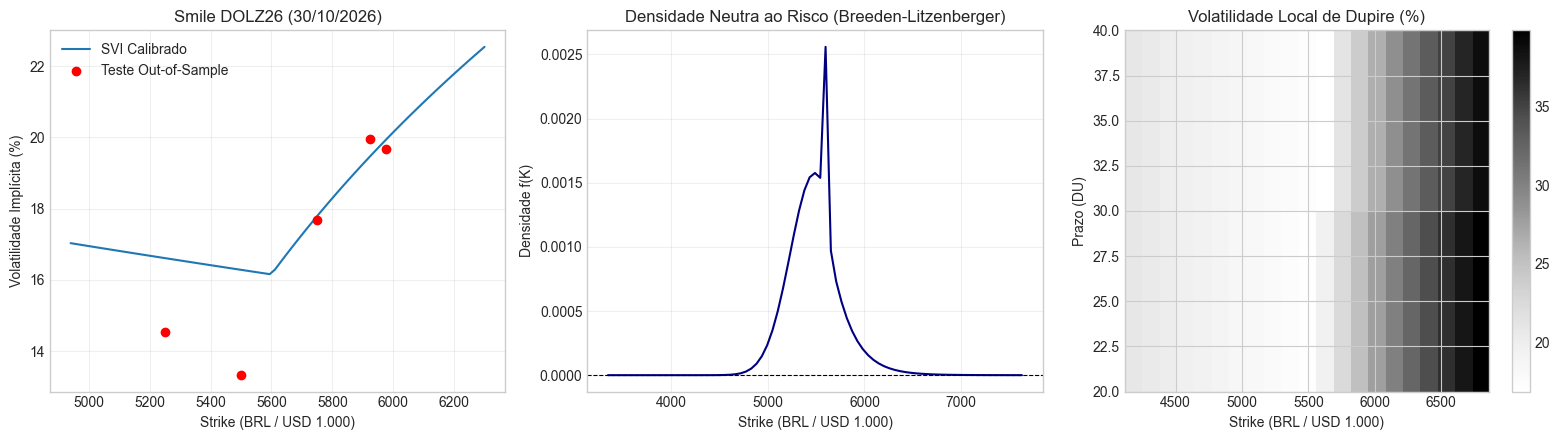

In [6]:
from bz_pricing.data.loaders import B3DataLoader
from bz_pricing.core.calendars import get_calendar
from bz_pricing.volatility import validate_slice_out_of_sample

ref_dt_3010 = datetime.date(2026, 10, 30)
loader = B3DataLoader(data_dir='dados/b3')
dol_opts = loader.load_options(ref_dt_3010, asst='DOL', only_priced=True, auto_download=False)
dolz_opts = dol_opts[dol_opts['XprtnDt'] == '2026-12-01'].sort_values('ExrcPric').reset_index(drop=True)

sprd_df = pd.read_csv('dados/b3/BVBG_SPRD_20261030.csv', sep=';', low_memory=False)
fwd_dolz = float(sprd_df.loc[sprd_df['TckrSymb'] == 'DOLZ26', 'AdjstdQt'].iloc[0])

curva_pre_3010 = CurveManager(loader=loader, allow_download=True).get_curve('PRE', ref_dt_3010)
mat_dolz = datetime.date(2026, 12, 1)
du_dolz = get_calendar().bizdays(ref_dt_3010, mat_dolz)
r_pre_cont = math.log(1.0 + curva_pre_3010.get_rate(du_dolz))

oos = validate_slice_out_of_sample(
    strikes=dolz_opts['ExrcPric'].values,
    market_prices=dolz_opts['RefPric'].values,
    option_types=dolz_opts['option_type'].values,
    forward=fwd_dolz,
    r_cont=r_pre_cont,
    du=du_dolz,
    model='svi',
    otm_only=True,
    vega_weighted=True,
)

print(f'Séries DOLZ26 avaliadas: {len(dolz_opts)} | DU={du_dolz} | Forward={fwd_dolz:.2f}')
print(f"Out-of-sample SVI -> RMSE Vol: {oos['rmse_vol_bps']:.2f} bps | MAE Vol: {oos['mae_vol_bps']:.2f} bps | RMSE Preço: {oos['rmse_price']:.4f}")

sl_dolz = oos['slice']
sl_long = SVISlice(a=sl_dolz.a * 2.1, b=sl_dolz.b * 1.9, rho=sl_dolz.rho, m=sl_dolz.m, sigma=sl_dolz.sigma * 1.1, T=(du_dolz * 2) / 252.0)
fwds_dol_2d = {du_dolz: fwd_dolz, du_dolz * 2: fwd_dolz * 1.01}
surf_dol = VolatilitySurface.from_svi_slices({du_dolz: sl_dolz, du_dolz * 2: sl_long}, slice_forwards=fwds_dol_2d)

wing_res = surf_dol.wing_slope_check()
bl_res = surf_dol.breeden_litzenberger_density(du_dolz, forward=fwd_dolz, r_cont=r_pre_cont)
dup_res = surf_dol.dupire_local_vol_grid(forward_by_du=fwds_dol_2d, r_cont_by_du=r_pre_cont)

print('Lee wing check passed:', wing_res['passed'], wing_res['slices'])
print(f"Breeden-Litzenberger -> passed={bl_res['passed']} | min_density={bl_res['min_density']:.6e} | integral={bl_res['integral']:.4f}")
print(f"Dupire local vol -> passed={dup_res['passed']} | min_local_var={dup_res['min_local_var']:.6f} | negative_nodes={dup_res['negative_nodes']}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
k_dense = np.linspace(dolz_opts['ExrcPric'].min() * 0.95, dolz_opts['ExrcPric'].max() * 1.05, 80)
axes[0].plot(k_dense, sl_dolz.implied_vol(np.log(k_dense / fwd_dolz)) * 100, label='SVI Calibrado')
axes[0].scatter(oos['test_strikes'], oos['test_market_vols'] * 100, color='red', zorder=5, label='Teste Out-of-Sample')
axes[0].set_title('Smile DOLZ26 (30/10/2026)')
axes[0].set_xlabel('Strike (BRL / USD 1.000)')
axes[0].set_ylabel('Volatilidade Implícita (%)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(bl_res['strikes'], bl_res['density'], color='navy')
axes[1].axhline(0.0, color='black', linestyle='--', linewidth=0.8)
axes[1].set_title('Densidade Neutra ao Risco (Breeden-Litzenberger)')
axes[1].set_xlabel('Strike (BRL / USD 1.000)')
axes[1].set_ylabel('Densidade f(K)')
axes[1].grid(True, alpha=0.3)

im = axes[2].imshow(dup_res['local_vol'] * 100, aspect='auto', origin='lower', extent=[dup_res['strikes'][0], dup_res['strikes'][-1], dup_res['dus'][0], dup_res['dus'][-1]])
axes[2].set_title('Volatilidade Local de Dupire (%)')
axes[2].set_xlabel('Strike (BRL / USD 1.000)')
axes[2].set_ylabel('Prazo (DU)')
fig.colorbar(im, ax=axes[2])
plt.tight_layout()
plt.show()


### 5.2 Validação 2D da Superfície de Volatilidade de Juros (`IDI` — 30/10/2026)

Nas opções de `IDI` em 30/10/2026 (`2027-01-04` com 26 *strikes* e `2027-04-01` com 14 *strikes*), o valor corrente do índice à vista não integra diretamente o arquivo de negociação. A referência *forward* de `2027-01-04` é obtida pela paridade *put-call* via `infer_forward_from_put_call_parity` com ponderação por liquidez e define o `IDI` à vista implícito para projetar o *forward* de `2027-04-01` ao longo da curva `PRE`.

Os ajustes de `SVISlice` e `SABRSlice` utilizam apenas séries fora e no dinheiro (`otm_only=True`), aplicam pesos proporcionais ao vega (`vega_weighted=True`) e avaliam tanto a interpolação central quanto a extrapolação nas asas (`split_mode='interpolation'` e `'wings'`). Em seguida, os *forwards* de cada vencimento são passados em `slice_forwards` na construção da superfície 2D e auditados em `check_no_arbitrage`.


In [7]:
idi_opts = loader.load_options(ref_dt_3010, asst='IDI', only_priced=True, auto_download=False)
cal_b3 = get_calendar()

du_jan = cal_b3.bizdays(ref_dt_3010, datetime.date(2027, 1, 4))
r_jan = math.log(1.0 + curva_pre_3010.get_rate(du_jan))
df_jan = math.exp(-r_jan * (du_jan / 252.0))
fwd_jan = infer_forward_from_put_call_parity(
    idi_opts[idi_opts['XprtnDt'] == '2027-01-04'],
    discount_factor=df_jan,
)
idi_spot_parity = fwd_jan * df_jan
print(f'Forward 2027-01-04 (paridade put-call): {fwd_jan:.2f} | IDI spot implícito: {idi_spot_parity:.2f}')

idi_slices_svi, idi_slices_sabr, idi_fwds, idi_rs = {}, {}, {}, {}
rows_idi = []
for exp_str in ['2027-01-04', '2027-04-01']:
    sub = idi_opts[idi_opts['XprtnDt'] == exp_str].sort_values('ExrcPric').reset_index(drop=True)
    exp_dt = pd.to_datetime(exp_str).date()
    du_i = cal_b3.bizdays(ref_dt_3010, exp_dt)
    r_i = math.log(1.0 + curva_pre_3010.get_rate(du_i))
    fwd_i = idi_spot_parity * math.exp(r_i * (du_i / 252.0))
    idi_fwds[du_i] = fwd_i
    idi_rs[du_i] = r_i

    for sp_mode in ['interpolation', 'wings']:
        oos_svi = validate_slice_out_of_sample(
            strikes=sub['ExrcPric'].values,
            market_prices=sub['RefPric'].values,
            option_types=sub['option_type'].values,
            forward=fwd_i,
            r_cont=r_i,
            du=du_i,
            model='svi',
            otm_only=True,
            vega_weighted=True,
            split_mode=sp_mode,
        )
        oos_sabr = validate_slice_out_of_sample(
            strikes=sub['ExrcPric'].values,
            market_prices=sub['RefPric'].values,
            option_types=sub['option_type'].values,
            forward=fwd_i,
            r_cont=r_i,
            du=du_i,
            model='sabr',
            otm_only=True,
            vega_weighted=True,
            split_mode=sp_mode,
        )
        if sp_mode == 'interpolation':
            idi_slices_svi[du_i] = oos_svi['slice']
            idi_slices_sabr[du_i] = oos_sabr['slice']
        rows_idi.append({
            'vencimento': exp_str,
            'du': du_i,
            'split_mode': sp_mode,
            'n_treino': len(oos_svi['train_strikes']),
            'n_teste': len(oos_svi['test_strikes']),
            'svi_rmse_bps': round(oos_svi['rmse_vol_bps'], 2),
            'sabr_rmse_bps': round(oos_sabr['rmse_vol_bps'], 2),
            'svi_rmse_preco': round(oos_svi['rmse_price'], 2),
            'sabr_rmse_preco': round(oos_sabr['rmse_price'], 2),
        })

display(pd.DataFrame(rows_idi))

surf_idi_svi = VolatilitySurface.from_svi_slices(idi_slices_svi, slice_forwards=idi_fwds)
surf_idi_sabr = VolatilitySurface.from_sabr_slices(idi_slices_sabr, slice_forwards=idi_fwds)
print('Auditoria 2D IDI (SVI):', surf_idi_svi.check_no_arbitrage(forward_by_du=idi_fwds, r_cont_by_du=idi_rs))
print('Auditoria 2D IDI (SABR):', surf_idi_sabr.check_no_arbitrage(forward_by_du=idi_fwds, r_cont_by_du=idi_rs))


Forward 2027-01-04 (paridade put-call): 550844.05 | IDI spot implícito: 539229.27


,vencimento,du,split_mode,n_treino,n_teste,svi_rmse_bps,sabr_rmse_bps,svi_rmse_preco,sabr_rmse_preco
0,2027-01-04,42,interpolation,11,8,6.29,3.39,26.67,4.29
1,2027-01-04,42,wings,13,6,4.07,2.25,0.36,1.97
2,2027-04-01,102,interpolation,8,4,0.24,0.24,1.51,1.50
3,2027-04-01,102,wings,8,4,0.55,0.60,2.53,2.67


Auditoria 2D IDI (SVI): {'passed': True, 'strike_monotonicity_violations': 0, 'butterfly_violations': 0, 'calendar_violations': 0}
Auditoria 2D IDI (SABR): {'passed': False, 'strike_monotonicity_violations': 0, 'butterfly_violations': 0, 'calendar_violations': 12}


### 5.3 Validação 2D em Opções de ETF/Ações via `COTAHIST` (`BOVA11` — 30/10/2026)

As opções listadas de `BOVA11` são carregadas do boletim oficial `COTAHIST` via `B3DataLoader.load_equity_options` nos três vencimentos de maior atividade (`2026-11-19`, `2026-12-18` e `2027-01-15`). Adota-se o corte mínimo de liquidez `TOTNEG >= 10` em vez de `TOTNEG >= 5` porque séries com apenas cinco negócios apresentam livro aberto e último negócio defasado em relação ao livro de ofertas, como ocorre em `BOVAM159` em 30/10/2026 (`LastPric` R\$ 4,79 frente a `PREOFC` R\$ 0,75 e `PREOFV` R\$ 4,80).

Cada fatia SVI é ajustada somente sobre contratos fora e no dinheiro com ponderação por vega, e os *forwards* de cada prazo são informados em `slice_forwards` para verificação de não arbitragem e cômputo da superfície local de Dupire em *moneyness* logarítmico constante.


In [8]:
bova_opts = loader.load_equity_options(ref_dt_3010, underlying='BOVA11', only_priced=True, auto_download=False)
spot_bova = float(bova_opts['spot_price'].iloc[0])
bova_liq = bova_opts[(bova_opts['TOTNEG'] >= 10) & (bova_opts['ExrcPric'].between(0.85 * spot_bova, 1.15 * spot_bova))].copy()

bova_slices, bova_fwds, bova_rs = {}, {}, {}
for exp_str in ['2026-11-19', '2026-12-18', '2027-01-15']:
    sub = bova_liq[bova_liq['XprtnDt'] == exp_str].copy()
    exp_dt = pd.to_datetime(exp_str).date()
    du_i = cal_b3.bizdays(ref_dt_3010, exp_dt)
    r_i = math.log(1.0 + curva_pre_3010.get_rate(du_i))
    fwd_i = spot_bova * math.exp(r_i * (du_i / 252.0))
    sub = sub.drop_duplicates(subset=['ExrcPric', 'option_type']).sort_values('ExrcPric').reset_index(drop=True)
    if len(sub) < 6:
        continue
    oos_b = validate_slice_out_of_sample(
        strikes=sub['ExrcPric'].values,
        market_prices=sub['RefPric'].values,
        option_types=sub['option_type'].values,
        forward=fwd_i,
        r_cont=r_i,
        du=du_i,
        model='svi',
        otm_only=True,
        vega_weighted=True,
    )
    bova_slices[du_i] = oos_b['slice']
    bova_fwds[du_i] = fwd_i
    bova_rs[du_i] = r_i
    print(f"BOVA11 {exp_str} (DU={du_i}, treino={len(oos_b['train_strikes'])}, teste={len(oos_b['test_strikes'])}) -> SVI OOS RMSE Vol: {oos_b['rmse_vol_bps']:.2f} bps | MAE Vol: {oos_b['mae_vol_bps']:.2f} bps | RMSE Preço: R$ {oos_b['rmse_price']:.4f}")

if len(bova_slices) >= 2:
    surf_bova = VolatilitySurface.from_svi_slices(bova_slices, slice_forwards=bova_fwds)
    arb_bova = surf_bova.check_no_arbitrage(forward_by_du=bova_fwds, r_cont_by_du=bova_rs)
    dup_bova = surf_bova.dupire_local_vol_grid(forward_by_du=bova_fwds, r_cont_by_du=bova_rs)
    print('Auditoria 2D BOVA11:', arb_bova)
    print(f"Dupire BOVA11 -> passed={dup_bova['passed']} | min_local_var={dup_bova['min_local_var']:.6f} | negative_nodes={dup_bova['negative_nodes']}")


BOVA11 2026-11-19 (DU=13, treino=24, teste=23) -> SVI OOS RMSE Vol: 55.24 bps | MAE Vol: 44.43 bps | RMSE Preço: R$ 0.0410


BOVA11 2026-12-18 (DU=33, treino=24, teste=23) -> SVI OOS RMSE Vol: 64.64 bps | MAE Vol: 41.50 bps | RMSE Preço: R$ 0.0917
BOVA11 2027-01-15 (DU=51, treino=6, teste=6) -> SVI OOS RMSE Vol: 59.58 bps | MAE Vol: 35.39 bps | RMSE Preço: R$ 0.1741
Auditoria 2D BOVA11: {'passed': False, 'strike_monotonicity_violations': 5, 'butterfly_violations': 0, 'calendar_violations': 1}
Dupire BOVA11 -> passed=False | min_local_var=-0.093042 | negative_nodes=2


## 6. Opções Exóticas, Taxas de Juros (`Swaption`, `CapFloor`) e Consistência Lote × Individual

Esta seção verifica quatro frentes complementares do núcleo de opções: a diferença entre as convenções periódica e zero-cupom B3 em `Swaption` com inversão *round-trip* em Black-76 e Bachelier, a decomposição por *caplet* e paridade `Cap - Floor` em `CapFloor`, o ajuste de monitoramento discreto de Broadie-Glasserman-Kou em `BarrierOption` (`monitoring_steps=252`) e fixações discretas em `AsianOption` (`n_fixings=12`), além da suavização par-ímpar da árvore CRR americana e da igualdade entre chamada individual e carteira em lote em `FXOption` avaliada sobre `VolatilitySurface`.


In [9]:
# 1. Swaption B3 zero-cupom vs periódica e Cap/Floor paridade
swp_zero = Swaption('SWP-DI-Z', expiry_date='2027-05-03', swap_maturity_date='2028-05-02', strike_rate=0.145, option_type='PAYER', swap_convention='b3_zero')
swp_per = Swaption('SWP-DI-P', expiry_date='2027-05-03', payment_dates=['2027-11-01', '2028-05-02'], strike_rate=0.145, option_type='PAYER', swap_convention='periodic')
m_swp_z = swp_zero.risk_metrics(ref_dt, curva_pre, vol=0.18, model='black76')
m_swp_b = swp_zero.risk_metrics(ref_dt, curva_pre, vol=0.015, model='bachelier')
iv_rt_blk = swp_zero.implied_volatility(ref_dt, m_swp_z['price'], curva_pre, model='black76')
iv_rt_bac = swp_zero.implied_volatility(ref_dt, m_swp_b['price'], curva_pre, model='bachelier')

cap_f = CapFloor('CAP-DI', fixing_dates=['2027-02-01', '2027-05-03'], payment_dates=['2027-05-03', '2027-08-02'], strike_rate=0.145, option_type='CAP')
flr_f = CapFloor('FLR-DI', fixing_dates=['2027-02-01', '2027-05-03'], payment_dates=['2027-05-03', '2027-08-02'], strike_rate=0.145, option_type='FLOOR')
p_cap = cap_f.price(ref_dt, curva_pre, vol=0.18)
p_flr = flr_f.price(ref_dt, curva_pre, vol=0.18)

# 2. Barreira com monitoramento contínuo vs discreto (BGK) e paridade in+out = vanilla
mat_ex = datetime.date(2027, 5, 17)
van_call = EquityOption('VAN40', mat_ex, strike=40.0, option_type='CALL', exercise='EUROPEAN')
do_cont = BarrierOption('DO-CONT', mat_ex, strike=40.0, barrier=32.0, option_type='CALL', barrier_type='down-and-out')
di_cont = BarrierOption('DI-CONT', mat_ex, strike=40.0, barrier=32.0, option_type='CALL', barrier_type='down-and-in')
do_disc = BarrierOption('DO-252', mat_ex, strike=40.0, barrier=32.0, option_type='CALL', barrier_type='down-and-out', monitoring_steps=252)

p_van = van_call.price(ref_dt, 38.5, curva_pre, vol=0.30, carry_or_div_yield=0.03)
p_do_c = do_cont.price(ref_dt, 38.5, curva_pre, vol=0.30, carry_or_div_yield=0.03)
p_di_c = di_cont.price(ref_dt, 38.5, curva_pre, vol=0.30, carry_or_div_yield=0.03)
p_do_d = do_disc.price(ref_dt, 38.5, curva_pre, vol=0.30, carry_or_div_yield=0.03)

# 3. Asiática geométrica e aritmética (contínua vs n_fixings=12) e suavização CRR americana
as_ac = AsianOption('AS-AC', mat_ex, strike=39.0, option_type='CALL', average_type='arithmetic')
as_ad = AsianOption('AS-A12', mat_ex, strike=39.0, option_type='CALL', average_type='arithmetic', n_fixings=12)
as_gd = AsianOption('AS-G12', mat_ex, strike=39.0, option_type='CALL', average_type='geometric', n_fixings=12)
p_ac = as_ac.price(ref_dt, 38.5, curva_pre, vol=0.30, carry_or_div_yield=0.03)
p_ad = as_ad.price(ref_dt, 38.5, curva_pre, vol=0.30, carry_or_div_yield=0.03)
p_gd = as_gd.price(ref_dt, 38.5, curva_pre, vol=0.30, carry_or_div_yield=0.03)

put_am = EquityOption('PETRP40', mat_ex, strike=40.0, option_type='PUT', exercise='AMERICAN')
crr_150 = put_am.price(ref_dt, 38.5, curva_pre, vol=0.32, carry_or_div_yield=0.04, crr_steps=150)
crr_151 = put_am.price(ref_dt, 38.5, curva_pre, vol=0.32, carry_or_div_yield=0.04, crr_steps=151)
crr_200 = put_am.price(ref_dt, 38.5, curva_pre, vol=0.32, carry_or_div_yield=0.04, crr_steps=200)

# 4. FXOption individual vs lote sobre VolatilitySurface (A1)
fx_surf = VolatilitySurface.from_delta_grid([21, 63], [0.25, 0.50, 0.75], [[0.19, 0.16, 0.18], [0.18, 0.155, 0.175]])
fx_test = FXOption('DOLC590', datetime.date(2027, 2, 1), strike=5.95, option_type='CALL')
p_fx_single = fx_test.price(ref_dt, spot_ptax=5.75, pre_rate_or_curve=curva_pre, cupom_limpo_or_curve=0.055, vol=fx_surf)
p_fx_batch = price_options_portfolio(
    [{'instrument': fx_test, 'spot_ptax': 5.75, 'pre_rate_or_curve': curva_pre, 'cupom_limpo_or_curve': 0.055, 'vol': fx_surf, 'quantity': 1}],
    ref_dt,
)['price'].iloc[0]

summary_sec6 = pd.DataFrame([
    {'verificacao': 'Swaption B3 Zero (Black-76) vs IV Roundtrip', 'valor_a': m_swp_z['price'], 'valor_b': iv_rt_blk, 'detalhe': f"fwd_swap={m_swp_z['forward_swap_rate']*100:.4f}%"},
    {'verificacao': 'Swaption B3 Zero (Bachelier) vs IV Roundtrip', 'valor_a': m_swp_b['price'], 'valor_b': iv_rt_bac, 'detalhe': f"vega_1bp=R$ {m_swp_b['vega_1bp']:.2f}"},
    {'verificacao': 'Swaption Periódica vs B3 Zero (preço)', 'valor_a': swp_per.price(ref_dt, curva_pre, 0.18), 'valor_b': m_swp_z['price'], 'detalhe': 'estruturas de cupom distintas'},
    {'verificacao': 'Cap vs Floor (2 períodos DI)', 'valor_a': p_cap, 'valor_b': p_flr, 'detalhe': f'caplets={len(cap_f.fixing_dates)}'},
    {'verificacao': 'Barrier Paridade In + Out = Vanilla', 'valor_a': p_do_c + p_di_c, 'valor_b': p_van, 'detalhe': f'DO discreta(252)={p_do_d:.6f} >= DO cont={p_do_c:.6f}'},
    {'verificacao': 'Asian Aritmética Contínua vs 12 Fixings', 'valor_a': p_ac, 'valor_b': p_ad, 'detalhe': f'Geom(12)={p_gd:.6f} <= Arith(12)'},
    {'verificacao': 'CRR Americana Suavizada (N=150 vs N=151)', 'valor_a': crr_150, 'valor_b': crr_151, 'detalhe': f'N=200={crr_200:.6f} | dif_150_151={abs(crr_150 - crr_151):.6e}'},
    {'verificacao': 'FXOption Individual vs Lote (VolatilitySurface)', 'valor_a': p_fx_single, 'valor_b': p_fx_batch, 'detalhe': f'dif={abs(p_fx_single - p_fx_batch):.2e}'},
])
display(summary_sec6)
assert abs((p_do_c + p_di_c) - p_van) < 1e-8
assert p_do_d >= p_do_c
assert p_gd <= p_ad
assert abs(p_fx_single - p_fx_batch) < 1e-12


,verificacao,valor_a,valor_b,detalhe
0,Swaption B3 Zero (Black-76) vs IV Roundtrip,6987.308327,0.180000,fwd_swap=14.7725%
1,Swaption B3 Zero (Bachelier) vs IV Roundtrip,4540.596998,0.015000,vega_1bp=R$ 21.26
2,Swaption Periódica vs B3 Zero (preço),4923.297957,6987.308327,estruturas de cupom distintas
3,Cap vs Floor (2 períodos DI),973.938765,5799.662087,caplets=2
4,Barrier Paridade In + Out = Vanilla,3.394133,3.394133,DO discreta(252)=3.314511 >= DO cont=3.297066
5,Asian Aritmética Contínua vs 12 Fixings,2.033648,2.186889,Geom(12)=2.094304 <= Arith(12)
6,CRR Americana Suavizada (N=150 vs N=151),3.527669,3.527768,N=200=3.528104 | dif_150_151=9.909409e-05
7,FXOption Individual vs Lote (VolatilitySurface),0.120866,0.120866,dif=0.00e+00


## 7. Referências Normativas e Bibliográficas

- **B3 S.A. – Brasil, Bolsa, Balcão.** *Manual de Apreçamento — Contratos de Opções*. São Paulo: B3, 2026. Disponível em: <https://www.b3.com.br/pt_br/market-data-e-indices/servicos-de-dados/market-data/consultas/mercado-de-derivativos/>.
- **B3 S.A. – Brasil, Bolsa, Balcão.** *Anexo de Parâmetros Mensais — Opções e Manual de Curvas*. São Paulo: B3. Disponível em: <https://www.b3.com.br/>.
- **Bloomberg L.P.** *Equity Implied Volatility Surface: Option Pricing & Risk Management*. New York: Bloomberg Finance L.P. Disponível em: <https://www.bloomberg.com/professional/>.